In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent / "src"))
import pandas as pd
import matplotlib.pyplot as plt
import config
from matplotlib.colors import LinearSegmentedColormap
from analysis import descriptive as ds

plt.style.use("seaborn-v0_8-whitegrid")

COLOURS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
BLUES = LinearSegmentedColormap.from_list(
    "blues", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
INK = "#52514e"
COUNTRY_NAMES = {"KHM": "Cambodia", "LAO": "Laos", "MMR": "Myanmar", "THA": "Thailand", "VNM": "Vietnam"}

In [2]:
cells = ds.build_cell_table()
totals = ds.monthly_fire_totals()

Grid cells in the study area: 16,383 (1,928,219 km2, 195 provinces)
Monthly totals: 1,179,576 rows | 5,009,341 hotspots, 1,662,408 fire cell-days, 6 years


In [3]:
summary = ds.country_summary(totals, cells)
summary.insert(1, "name", summary["country"].map(COUNTRY_NAMES))
summary

,country,name,cells,area_km2,hotspots_per_year,rank_by_total,hotspots_per_1000km2,rank_by_density,fire_days_per_cell
0,KHM,Cambodia,1508,182267.0,140634.0,3,771.6,1,28.58
1,LAO,Laos,1956,229704.0,163054.0,2,709.8,2,22.38
2,MMR,Myanmar,5787,667465.0,339549.0,1,508.7,3,18.22
3,THA,Thailand,4331,517247.0,137488.0,4,265.8,4,13.24
4,VNM,Vietnam,2801,331536.0,54165.0,5,163.4,5,9.80


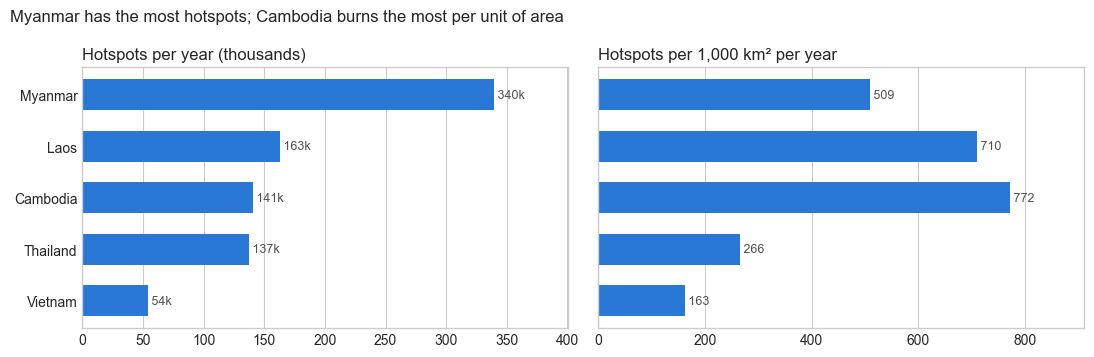

In [4]:
order = summary.sort_values("hotspots_per_year", ascending=True)
labels = order["name"]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].barh(labels, order["hotspots_per_year"] / 1000, color=COLOURS[0], height=0.6)
axes[0].set_title("Hotspots per year (thousands)", loc="left")
axes[1].barh(labels, order["hotspots_per_1000km2"], color=COLOURS[0], height=0.6)
axes[1].set_title("Hotspots per 1,000 km² per year", loc="left")

for ax, column, scale, fmt in [(axes[0], "hotspots_per_year", 1000, "{:,.0f}k"), (axes[1], "hotspots_per_1000km2", 1, "{:,.0f}")]:
    for y, value in enumerate(order[column] / scale):
        ax.text(value, y, " " + fmt.format(value), va="center", fontsize=9, color=INK)
    ax.set_xlim(0, (order[column] / scale).max() * 1.18)
    ax.grid(axis="y", visible=False)

axes[1].set_yticklabels([])
fig.suptitle("Myanmar has the most hotspots; Cambodia burns the most per unit of area", x=0.01, ha="left", fontsize=12)
plt.tight_layout()
plt.show()

In [5]:
by_year = ds.country_by_year(totals, cells)
by_year

country,KHM,LAO,MMR,THA,VNM
year,,,,,
2020,1124.3,776.0,612.9,431.4,214.1
2021,904.8,546.7,520.0,221.6,166.4
2022,502.2,518.5,343.9,107.1,113.7
2023,660.9,1125.9,628.0,352.5,176.4
2024,841.2,761.1,500.2,279.4,180.2
2025,596.2,530.8,447.3,202.8,129.5


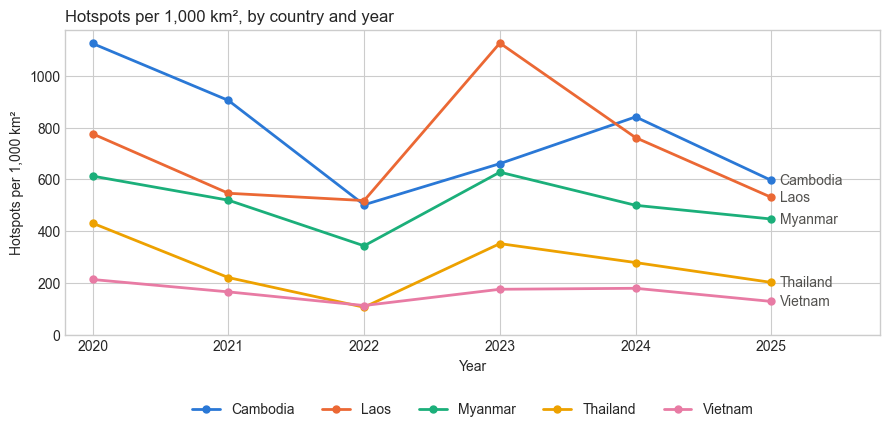

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.5))
last_year = by_year.index[-1]
order_by_last = by_year.loc[last_year].sort_values(ascending=False).index.tolist()
for number, country in enumerate(order_by_last):
    ax.plot(by_year.index, by_year[country], color=COLOURS[number], linewidth=2, marker="o", markersize=5, label=COUNTRY_NAMES[country])
    ax.annotate(COUNTRY_NAMES[country], (last_year, by_year.loc[last_year, country]), xytext=(6, 0), textcoords="offset points", va="center", fontsize=10, color=INK)
ax.set_title("Hotspots per 1,000 km², by country and year", loc="left")
ax.set_xlabel("Year")
ax.set_ylabel("Hotspots per 1,000 km²")
ax.set_xticks(by_year.index)
ax.set_xlim(by_year.index[0] - 0.2, last_year + 0.8)
ax.set_ylim(bottom=0)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=5, frameon=False)
plt.tight_layout()
plt.show()

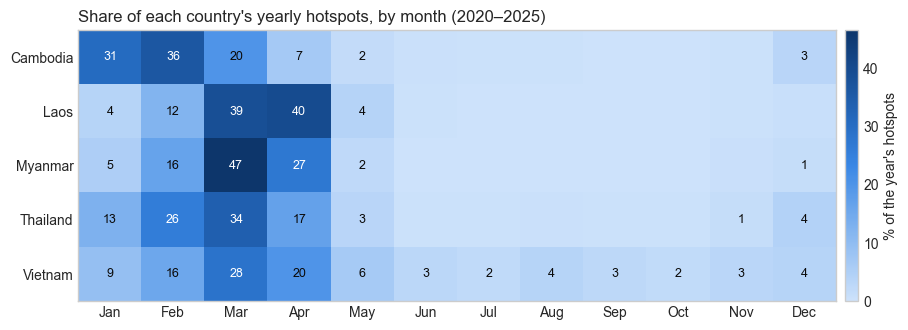

In [7]:
profile = ds.seasonal_profile(totals, cells)
profile.index = [COUNTRY_NAMES[c] for c in profile.index]

fig, ax = plt.subplots(figsize=(10, 3.4))
image = ax.imshow(profile.values, cmap=BLUES, aspect="auto", vmin=0, vmax=profile.values.max())
ax.set_xticks(range(len(profile.columns)))
ax.set_xticklabels(profile.columns)
ax.set_yticks(range(len(profile.index)))
ax.set_yticklabels(profile.index)
ax.grid(False)
for row in range(profile.shape[0]):
    for col in range(profile.shape[1]):
        value = profile.values[row, col]
        if value >= 1:
            colour = "white" if value > profile.values.max() * 0.55 else "#0b0b0b"
            ax.text(col, row, f"{value:.0f}", ha="center", va="center", fontsize=9, color=colour)
fig.colorbar(image, ax=ax, label="% of the year's hotspots", pad=0.01)
ax.set_title("Share of each country's yearly hotspots, by month (2020–2025)", loc="left")
plt.tight_layout()
fig.savefig(config.FIGURES_DIR / "fire_season_by_country.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
season = ds.fire_season(ds.seasonal_profile(totals, cells))
season.insert(1, "name", season["country"].map(COUNTRY_NAMES))
season

,country,name,peak_month,peak_share_pct,season_months,season_share_pct
0,KHM,Cambodia,Feb,36.3,"Jan, Feb, Mar",86.9
1,LAO,Laos,Apr,39.8,"Feb, Mar, Apr",90.6
2,MMR,Myanmar,Mar,46.6,"Feb, Mar, Apr",90.3
3,THA,Thailand,Mar,34.0,"Jan, Feb, Mar, Apr",89.4
4,VNM,Vietnam,Mar,28.5,"Feb, Mar, Apr",64.0


In [9]:
landcover = ds.by_landcover(totals, cells)
landcover

,land_cover_dominant,cells,share_of_cells_pct,share_of_hotspots_pct,fire_days_per_cell,hotspots_per_1000km2
0,grassland,484,3.0,4.6,27.44,678.3
1,cropland,3859,23.6,16.5,17.50,301.2
2,forest,11672,71.2,78.4,16.64,478.0
3,other,368,2.2,0.5,5.46,88.1


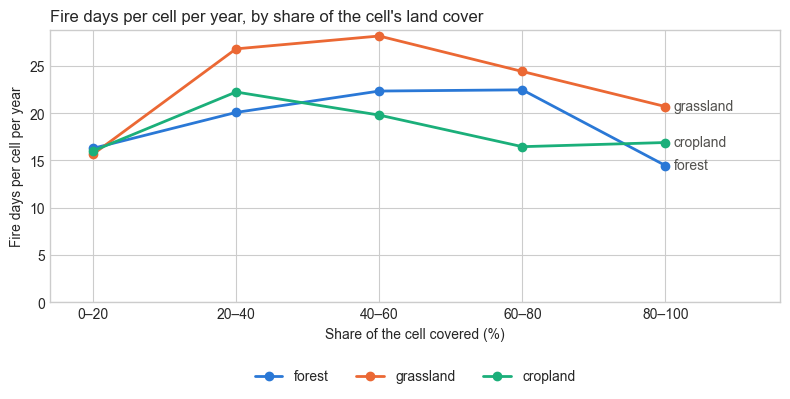

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.2))
for number, column in enumerate(["forest_pct", "grassland_pct", "cropland_pct"]):
    table = ds.by_landcover_share(totals, cells, column)
    x_labels = ["0–20", "20–40", "40–60", "60–80", "80–100"]
    name = column.replace("_pct", "")
    ax.plot(x_labels, table["fire_days_per_cell"], color=COLOURS[number], linewidth=2, marker="o", markersize=6, label=name)
    ax.annotate(name, (len(x_labels) - 1, table["fire_days_per_cell"].iloc[-1]), xytext=(6, 0),
                textcoords="offset points", va="center", fontsize=10, color=INK)
ax.set_title("Fire days per cell per year, by share of the cell's land cover", loc="left")
ax.set_xlabel("Share of the cell covered (%)")
ax.set_ylabel("Fire days per cell per year")
ax.set_ylim(bottom=0)
ax.set_xlim(-0.3, 4.8)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, frameon=False)
plt.tight_layout()
plt.show()

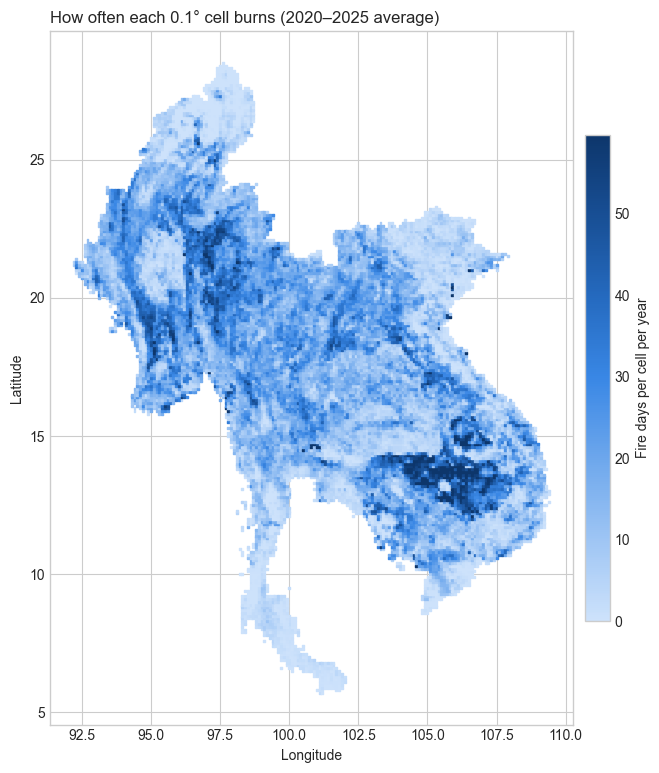

In [11]:
density = ds.cell_density(totals, cells)

fig, ax = plt.subplots(figsize=(7, 8.5))
points = ax.scatter(density["longitude"], density["latitude"], c=density["fire_days_per_year"],
                    cmap=BLUES, s=2, marker="s", vmin=0, vmax=density["fire_days_per_year"].quantile(0.99))
fig.colorbar(points, ax=ax, label="Fire days per cell per year", shrink=0.6, pad=0.02)
ax.set_title("How often each 0.1° cell burns (2020–2025 average)", loc="left")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_aspect("equal")
plt.tight_layout()
fig.savefig(config.FIGURES_DIR / "fire_density_map.png", dpi=150, bbox_inches="tight")
plt.show()

In [12]:
provinces = ds.province_summary(totals, cells)
print(f"Provinces and states ranked (area at least 2,000 km²): {len(provinces)}")
provinces.head(10)

Provinces and states ranked (area at least 2,000 km²): 167


,province,country,cells,area_km2,hotspots_per_year,hotspots_per_1000km2,fire_days_per_cell
0,Preah Vihear,KHM,114,13718.0,23688.0,1726.8,53.02
1,Stung Treng,KHM,94,11313.0,19055.0,1684.4,47.37
2,Kayah State,MMR,100,11701.0,15650.0,1337.5,33.05
3,Kratié,KHM,104,12575.0,16595.0,1319.7,42.18
4,Mondulkiri,KHM,111,13415.0,16622.0,1239.0,38.27
5,Ratanakiri,KHM,101,12154.0,13068.0,1075.2,34.90
6,Oudomxay,LAO,100,11612.0,12478.0,1074.6,21.08
7,Oddar Meanchey,KHM,30,3604.0,3600.0,998.9,43.93
8,Luang Prabang,LAO,169,19662.0,19580.0,995.8,23.08
9,Attapeu,LAO,75,8986.0,8171.0,909.3,31.76


In [13]:
top_total = provinces.sort_values("hotspots_per_year", ascending=False).head(5)
top_total[["province", "country", "hotspots_per_year", "hotspots_per_1000km2", "fire_days_per_cell"]]

,province,country,hotspots_per_year,hotspots_per_1000km2,fire_days_per_cell
15,Shan State,MMR,117995.0,757.1,25.49
53,Sagaing,MMR,37655.0,390.6,14.34
10,Chin State,MMR,33372.0,873.3,19.53
17,Magway,MMR,31215.0,673.5,23.75
0,Preah Vihear,KHM,23688.0,1726.8,53.02


In [14]:
myanmar_total = summary.loc[summary["country"] == "MMR", "hotspots_per_year"].iloc[0]
shan = provinces.loc[provinces["province"] == "Shan State"].iloc[0]
print(f"Shan State: {shan['hotspots_per_year']:,.0f} hotspots per year = {shan['hotspots_per_year'] / myanmar_total * 100:.0f}% of Myanmar's total")

cells_ranked = density.sort_values("fire_days_per_year", ascending=False)
top_cells = cells_ranked.head(10)
print(f"The 10 most frequently burning cells: {top_cells['fire_days_per_year'].min():.0f}-{top_cells['fire_days_per_year'].max():.0f} fire days per year")
top_cells[["grid_id", "country", "province", "fire_days_per_year", "hotspots_per_year"]]

Shan State: 117,995 hotspots per year = 35% of Myanmar's total
The 10 most frequently burning cells: 92-183 fire days per year


,grid_id,country,province,fire_days_per_year,hotspots_per_year
3691,14.6_101.1,THA,Saraburi,183.17,445.3
3690,14.6_101.0,THA,Saraburi,165.17,272.2
3800,14.7_100.8,THA,Saraburi,123.83,179.8
12440,21.6_96.2,MMR,Mandalay,123.33,187.8
5326,16.0_97.7,MMR,Mon State,121.17,215.7
13410,22.4_96.7,MMR,Shan State,108.83,225.7
3688,14.6_100.8,THA,Saraburi,102.83,134.7
11514,21.0_106.5,VNM,Hải Dương,101.00,211.8
82,10.3_104.6,VNM,Kiên Giang,100.00,128.0
2743,13.7_106.7,KHM,Ratanakiri,91.50,529.2
